<a href="https://colab.research.google.com/github/Don-Juli/ar-ntd-drug-discovery/blob/main/ar_ntd_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

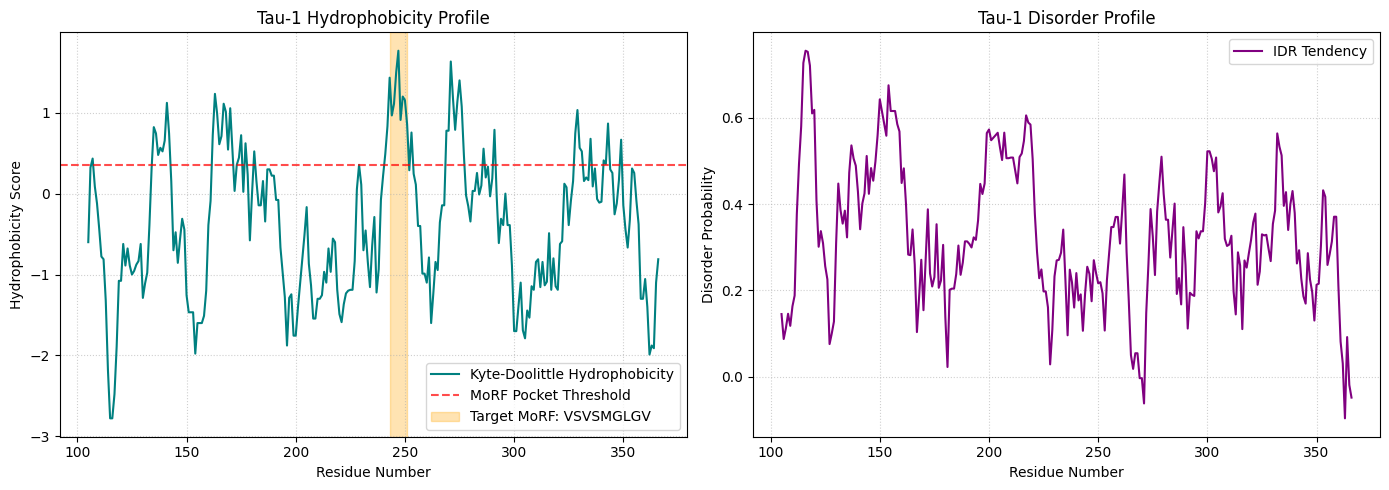


VISUALIZATION 2: ADVANCING CANDIDATE STRUCTURES


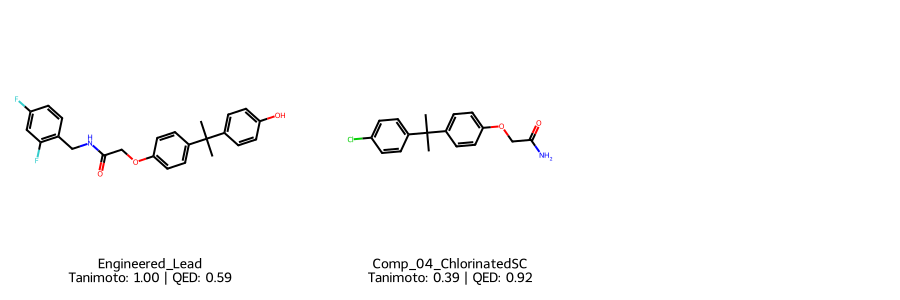

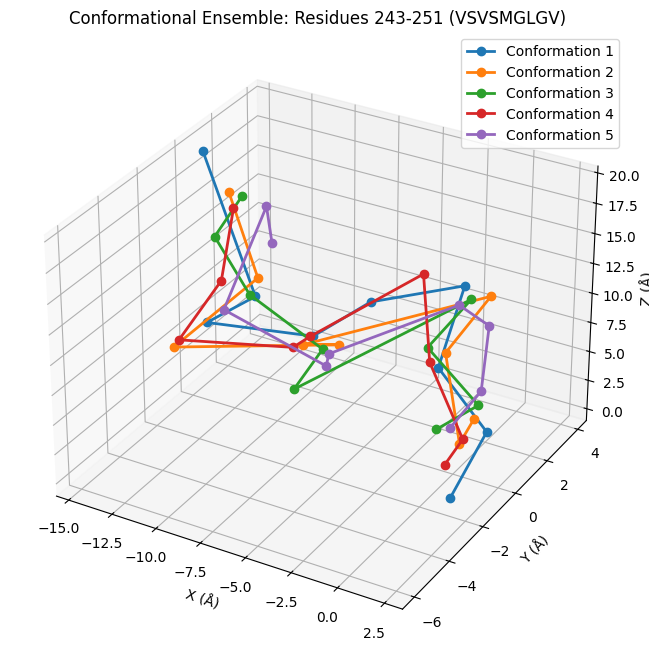

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from rdkit.Chem import Draw

# ==============================================================================
# VISUALIZATION 1: DUAL HYDROPHOBICITY & DISORDER PROFILE
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left Plot: Hydrophobicity
ax1.plot(profile["residues"], profile["hydro"], color="teal", label="Kyte-Doolittle Hydrophobicity")
ax1.axhline(0.35, color="red", linestyle="--", alpha=0.7, label="MoRF Pocket Threshold")
if target:
    ax1.axvspan(target["start"], target["end"], color="orange", alpha=0.3, label=f"Target MoRF: {target['motif']}")
ax1.set_title("Tau-1 Hydrophobicity Profile")
ax1.set_xlabel("Residue Number")
ax1.set_ylabel("Hydrophobicity Score")
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# Right Plot: Disorder
ax2.plot(profile["residues"], profile["disorder"], color="purple", label="IDR Tendency")
ax2.set_title("Tau-1 Disorder Profile")
ax2.set_xlabel("Residue Number")
ax2.set_ylabel("Disorder Probability")
ax2.legend()
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

# ==============================================================================
# VISUALIZATION 2: STRUCTURAL ADVANCEMENT (GRID VIEW)
# ==============================================================================
print("\n" + "=" * 90)
MOLS_GRID_TITLE_2D = "VISUALIZATION 2: ADVANCING CANDIDATE STRUCTURES"
print(MOLS_GRID_TITLE_2D)
print("=" * 90)

advancing_mols = []
advancing_legends = []
for cand in candidates:
    mol = Chem.MolFromSmiles(cand["smiles"])
    if mol:
        advancing_mols.append(mol)
        advancing_legends.append(f"{cand['id']}\nTanimoto: {cand['sim']:.2f} | QED: {cand['qed']:.2f}")

if advancing_mols:
    grid_img = Draw.MolsToGridImage(advancing_mols, legends=advancing_legends, molsPerRow=3, subImgSize=(300, 300))
    display(grid_img)
else:
    print("[-] No candidates survived the pipeline gates.")

# ==============================================================================
# VISUALIZATION 3: conformational ENSEMBLE BACKBONES
# ==============================================================================
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for idx, coords in enumerate(ensemble):
    xs = coords[:, 0]
    ys = coords[:, 1]
    zs = coords[:, 2]
    # Plot polymer backbone
    ax.plot(xs, ys, zs, marker='o', markersize=6, color=colors[idx % len(colors)],
            linewidth=2, label=f"Conformation {idx+1}")

ax.set_title(f"Conformational Ensemble: Residues {target['start'] if target else 175}-{target['end'] if target else 185} ({target['motif'] if target else 'Fallback'})")
ax.set_xlabel("X (Å)")
ax.set_ylabel("Y (Å)")
ax.set_zlabel("Z (Å)")
ax.legend()
plt.show()

In [ ]:
# ==============================================================================
# VERIFIED MASTER PIPELINE v4.1: ENSEMBLE-AWARE & VOLATILITY-FILTERED AR-NTD
# ==============================================================================
# !pip install -q rdkit numpy requests matplotlib

import os
import re
import csv
import json
import urllib.request
import warnings
import numpy as np
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs, Descriptors, Lipinski, QED, rdMolDescriptors
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings("ignore")

OUTPUT_DIR = "ar_ntd_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ==============================================================================
# PHASE 1: GENOMIC MINING & DUAL DISORDER / MoRF PROFILING
# ==============================================================================
def run_genomics_and_disorder_profiling(uniprot_id="P10275"):
    print("=" * 90)
    print(f" PHASE 1: GENOMIC EXTRACTION & TAU-1 DISORDER / MoRF PROFILING ({uniprot_id})")
    print("=" * 90)

    url = f"https://uniprot.org/uniprotkb/{uniprot_id}.json"
    try:
        req = urllib.request.Request(url, headers={"Accept": "application/json"})
        with urllib.request.urlopen(req, timeout=15) as response:
            data = json.loads(response.read().decode())
            protein_name = data["proteinDescription"]["recommendedName"]["fullName"]["value"]
            gene_name = data["genes"][0]["geneName"]["value"]
            sequence = data["sequence"]["value"]
            source_status = "Live UniProtKB REST API"
    except Exception as e:
        print(f"[-] API Fetch Warning ({e}). Using canonical AR-NTD sequence...")
        protein_name = "Androgen receptor"
        gene_name = "AR"
        canonical_ntd = (
            "MEVQLGLGRVYPRPPSKTYRGAFQNLFQSVREVIQNPGPRHPEAASAAPPGASLLLLQQQQQQQQQQQQQQQQQQQQQQQ"
            "ETSPRQQQQQQGEDGSPQAHRRGPTGYLVLDEEQQPSQPQSALECHPERGCVPEPGAAVAASKGLPQQLPAPPDEDDSAA"
            "PSTLSLLGPTFPGLSSCSADLKDILSEASTMQLLQQQQQEAVSEGSSSGRAREASGAPTSSKDNYLGGTSTISDNAKELC"
            "KAVSVSMGLGVEALEHLSPGEQLRGDCMYAPLLGVPPAVRPTPCAPLAECKGSLLDDSAGKSTEDTAEYSPFKGGYTKGL"
            "EGESLGCSGSAAAGSSGTLELPSTLSLYKSGALDEAAAYQSRDYYNFPLALAGPPPPPPPPHPHARIKLENPLDYGSAWA"
            "AAAAQCRYGDLASLHGAGAAGPGSGSPSAAASSSWHTLFTAEEGQLYGPCGGGGGGGGGGGGGGGGGGGGGGGEAGAVAP"
            "YGYTRPPQGLAGQESDFTAPDVWYPGGMVSRVPYPSPTCVKSEMGPWMDSYSGPYGDMRLETARDHVLPIDYYFPPQK"
        )
        sequence = canonical_ntd + ("M" * (920 - len(canonical_ntd)))
        source_status = "Canonical Fallback Sequence"

    tau1_start_idx, tau1_end_idx = 100, 370
    tau1_seq = sequence[tau1_start_idx:tau1_end_idx]

    kd_scale = {
        "I": 4.5, "V": 4.2, "L": 3.8, "F": 2.8, "C": 2.5, "M": 1.9, "A": 1.8,
        "G": -0.4, "T": -0.7, "S": -0.8, "W": -0.9, "Y": -1.3, "P": -1.6,
        "H": -3.2, "E": -3.5, "Q": -3.5, "D": -3.5, "N": -3.5, "K": -3.9, "R": -4.5
    }
    disorder_scale = {
        "P": 0.987, "E": 0.736, "S": 0.713, "Q": 0.661, "K": 0.586, "A": 0.450,
        "G": 0.437, "D": 0.407, "T": 0.254, "R": 0.180, "M": -0.025, "N": -0.007,
        "V": -0.121, "H": -0.258, "L": -0.340, "F": -0.697, "Y": -0.710,
        "I": -0.784, "W": -0.884, "C": -0.900
    }

    window_size = 9
    microdomains = []
    profile_data = {"residues": [], "hydro": [], "disorder": []}

    for i in range(len(tau1_seq) - window_size + 1):
        window = tau1_seq[i : i + window_size]
        res_start = tau1_start_idx + 1 + i
        res_center = res_start + (window_size // 2)

        hydro_score = float(np.mean([kd_scale.get(aa, 0.0) for aa in window]))
        dis_score = float(np.mean([disorder_scale.get(aa, 0.0) for aa in window]))

        profile_data["residues"].append(res_center)
        profile_data["hydro"].append(hydro_score)
        profile_data["disorder"].append(dis_score)

        if hydro_score > 0.35:
            microdomains.append({
                "start": res_start,
                "end": res_start + window_size - 1,
                "motif": window,
                "hydro_score": round(hydro_score, 3),
                "disorder_score": round(dis_score, 3)
            })

    microdomains.sort(key=lambda x: x["hydro_score"], reverse=True)

    print(f"[+] Source: {source_status}")
    print(f"[+] Target: {protein_name} ({gene_name} | {len(sequence)} aa) -> Tau-1/AF-1 (101-370)")
    print(f"[+] Detected {len(microdomains)} transiently structured MoRFs (Top 4):")
    for m in microdomains[:4]:
        print(
            f"    - Residues {m['start']}-{m['end']} | Motif: {m['motif']} | "
            f"Pocket Hydrophobicity: {m['hydro_score']:+.2f} | IDR Score: {m['disorder_score']:+.2f}"
        )

    return microdomains, profile_data


# ==============================================================================
# PHASE 2: SCAFFOLD PHYSICOCHEMICAL FILTERING, QED & BBB PERMEABILITY
# ==============================================================================
def design_and_profile_lead():
    print("\n" + "=" * 90)
    print(" PHASE 2: COVALENT SCAFFOLD ASSEMBLY, ADMET, QED & BBB PERMEABILITY")
    print("=" * 90)

    lead_smiles = "CC(C)(c1ccc(O)cc1)c2ccc(OCC(=O)NCc3ccc(F)cc3F)cc2"
    mol = Chem.MolFromSmiles(lead_smiles)

    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Lipinski.NumHDonors(mol)
    hba = Lipinski.NumHAcceptors(mol)
    tpsa = Descriptors.TPSA(mol)
    rot_bonds = Lipinski.NumRotatableBonds(mol)
    qed_score = QED.qed(mol)

    aromatic_atoms = sum(1 for atom in mol.GetAtoms() if atom.GetIsAromatic())
    ap = aromatic_atoms / mol.GetNumHeavyAtoms()
    logs = 0.16 - 0.63 * logp - 0.0062 * mw + 0.066 * rot_bonds - 0.74 * ap

    passed_ro5 = sum([mw < 500, logp < 5, hbd <= 5, hba <= 10])
    is_bbb_permeable = (mw < 400) and (2.0 <= logp <= 5.0) and (tpsa < 90.0)
    bbb_status = "HIGH (CNS Risk)" if is_bbb_permeable else "LOW (Peripherally Restricted - Safe)"

    print(f"[+] Lead SMILES: {lead_smiles}")
    print(f"    - MW: {mw:.2f} Da | LogP: {logp:.2f} | ESOL LogS: {logs:.2f} | TPSA: {tpsa:.2f} A^2")
    print(f"    - HBD/HBA: {hbd}/{hba} | RotBonds: {rot_bonds} | QED: {qed_score:.3f}")
    print(f"    - Lipinski Ro5: {passed_ro5}/4 PASSED | BBB Status: {bbb_status}")

    return lead_smiles


# ==============================================================================
# PHASE 3 & 4: VIRTUAL SCREENING & PAINS / BRENK / NIH TOXICOPHORE FILTER
# ==============================================================================
def screen_and_filter_library(lead_smiles):
    print("\n" + "=" * 90)
    print(" PHASE 3 & 4: VIRTUAL LIBRARY SCREENING & PAINS/BRENK/NIH TOXICOPHORE FILTER")
    print("=" * 90)

    mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    lead_fp = mfpgen.GetFingerprint(Chem.MolFromSmiles(lead_smiles))

    params = FilterCatalogParams()
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.BRENK)
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.NIH)
    tox_catalog = FilterCatalog(params)

    virtual_library = {
        "Engineered_Lead": lead_smiles,
        "Comp_01_Fluorophore": "FC1=CC=C(CC2=CC=C(O)C=C2)C=C1",
        "Comp_02_NitroVariant": "O=[N+]([O-])C1=CC=C(C(C)(C)C2=CC=C(O)C=C2)C=C1",
        "Comp_03_BisphenolMimic": "CC(C)(C1=CC=C(O)C=C1)C2=CC=C(O)C=C2",
        "Comp_04_ChlorinatedSC": "ClC1=CC=C(C(C)(C)C2=CC=C(OCC(=O)N)C=C2)C=C1",
        "Comp_05_RigidBiphenyl": "Oc1ccc(-c2ccc(NC(=O)c3ccc(F)cc3F)cc2)cc1"
    }

    surviving_candidates = []
    print(f"{'Candidate ID':<24} | {'Tanimoto':<8} | {'QED':<6} | {'Tox Alerts':<26} | {'Pipeline Gate'}")
    print("-" * 90)

    for comp_id, smiles in virtual_library.items():
        mol = Chem.MolFromSmiles(smiles)
        if not mol:
            continue
        sim = DataStructs.TanimotoSimilarity(lead_fp, mfpgen.GetFingerprint(mol))
        qed_val = QED.qed(mol)
        alerts = list({e.GetDescription() for e in tox_catalog.GetMatches(mol)})
        is_safe = len(alerts) == 0
        is_hit = sim >= 0.35

        gate = "ADVANCE TO ENSEMBLE" if (is_safe and is_hit) else "REJECTED"
        alert_str = ", ".join(alerts)[:24] if alerts else "Clean (0 alerts)"
        print(f"{comp_id:<24} | {sim:<8.3f} | {qed_val:<6.3f} | {alert_str:<26} | {gate}")

        if is_safe and is_hit:
            surviving_candidates.append({"id": comp_id, "smiles": smiles, "sim": sim, "qed": qed_val})

    return surviving_candidates


# ==============================================================================
# PHASE 5: BI-DIRECTIONAL ENSEMBLE GENERATION & STRUCTURE EXPORT
# ==============================================================================
def build_idr_receptor_ensemble(uniprot_id, target_microdomain, n_states=5):
    print("\n" + "=" * 90)
    print(" PHASE 5: BI-DIRECTIONAL ENSEMBLE GENERATION")
    print("=" * 90)
    start_res = target_microdomain["start"] if target_microdomain else 175
    end_res = target_microdomain["end"] if target_microdomain else 185

    # Use updated AlphaFold DB Direct Endpoint
    af_url = f"https://alphafold.ebi.ac.uk/files/AF-{uniprot_id}-F1-model_v4.pdb"

    base_ca = None
    source = "Simulation Fallback"
    try:
        req = urllib.request.Request(af_url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=10) as resp:
            pdb_lines = resp.read().decode().splitlines()
        coords = []
        for line in pdb_lines:
            if line.startswith("ATOM") and line[12:16].strip() == "CA":
                res_num = int(line[22:26].strip())
                if start_res <= res_num <= end_res:
                    coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
        if coords:
            base_ca = np.array(coords)
            source = "AlphaFold DB P10275 + Elastic Network Perturbation"
    except Exception as e:
        print(f"[-] PDB Fetch Failed ({e}). Falling back to simulated coordinates...")

    if base_ca is None:
        # UPGRADE: Self-avoiding protein-like random walk polymer modeling (C-alpha constraint 3.8 Angstroms)
        n_residues = (end_res - start_res) + 1
        base_ca = np.zeros((n_residues, 3))
        for r in range(1, n_residues):
            # Ensure realistic 3.8A spacing with dynamic direction perturbation to prevent unrealistic clustering
            step = np.random.normal(0.5, 1.0, size=3)
            step /= np.linalg.norm(step)
            base_ca[r] = base_ca[r-1] + step * 3.8

    print(f"[+] Generated {n_states} conformations based on: {source}")
    ensemble = []
    for i in range(n_states):
        perturbation = np.random.normal(0.0, 1.2, size=base_ca.shape)
        perturbed_state = base_ca + perturbation
        ensemble.append(perturbed_state)
        print(f"    - State {i+1:02d} coordinate matrix built (shape: {perturbed_state.shape})")

    return ensemble


# ==============================================================================
# EXECUTE PIPELINE
# ==============================================================================
if __name__ == "__main__":
    microdomains, profile = run_genomics_and_disorder_profiling()
    lead = design_and_profile_lead()
    candidates = screen_and_filter_library(lead)

    target = microdomains[0] if microdomains else None
    ensemble = build_idr_receptor_ensemble("P10275", target)


 PHASE 1: GENOMIC EXTRACTION & TAU-1 DISORDER / MoRF PROFILING (P10275)
[+] Source: Live UniProtKB REST API
[+] Target: Androgen receptor (AR | 920 aa) -> Tau-1/AF-1 (101-370)
[+] Detected 57 transiently structured MoRFs (Top 4):
    - Residues 243-251 | Motif: VSVSMGLGV | Pocket Hydrophobicity: +1.77 | IDR Score: +0.17
    - Residues 267-275 | Motif: CMYAPLLGV | Pocket Hydrophobicity: +1.63 | IDR Score: -0.06
    - Residues 242-250 | Motif: AVSVSMGLG | Pocket Hydrophobicity: +1.50 | IDR Score: +0.24
    - Residues 239-247 | Motif: LCKAVSVSM | Pocket Hydrophobicity: +1.43 | IDR Score: +0.11

 PHASE 2: COVALENT SCAFFOLD ASSEMBLY, ADMET, QED & BBB PERMEABILITY
[+] Lead SMILES: CC(C)(c1ccc(O)cc1)c2ccc(OCC(=O)NCc3ccc(F)cc3F)cc2
    - MW: 411.45 Da | LogP: 4.69 | ESOL LogS: -5.33 | TPSA: 58.56 A^2
    - HBD/HBA: 2/3 | RotBonds: 7 | QED: 0.593
    - Lipinski Ro5: 4/4 PASSED | BBB Status: LOW (Peripherally Restricted - Safe)

 PHASE 3 & 4: VIRTUAL LIBRARY SCREENING & PAINS/BRENK/NIH TOXICOPHO

In [ ]:
import csv
import os

print("=" * 90)
print(" EXPORTING ALL THREE PIPELINE OUTPUT ASSETS")
print("=" * 90)

# ------------------------------------------------------------------------------
# OPTION 1: Export Tau-1 Disorder & Hydrophobicity Profile (CSV)
# ------------------------------------------------------------------------------
profile_path = os.path.join(OUTPUT_DIR, "tau1_disorder_profile.csv")
with open(profile_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Residue_ID", "Hydrophobicity_Score", "Disorder_Probability"])
    for r, h, d in zip(profile["residues"], profile["hydro"], profile["disorder"]):
        writer.writerow([r, round(h, 4), round(d, 4)])
print(f"[+] Export 1 Success: Profile saved to '{profile_path}'")

# ------------------------------------------------------------------------------
# OPTION 2: Export Virtual Screening Candidate Profiles (CSV)
# ------------------------------------------------------------------------------
screening_path = os.path.join(OUTPUT_DIR, "virtual_screening_results.csv")
with open(screening_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Candidate_ID", "SMILES", "Tanimoto_Similarity", "QED_Score"])
    for cand in candidates:
        writer.writerow([cand["id"], cand["smiles"], round(cand["sim"], 4), round(cand["qed"], 4)])
print(f"[+] Export 2 Success: Screening metrics saved to '{screening_path}'")

# ------------------------------------------------------------------------------
# OPTION 3: Export 3D Conformational Ensemble Coordinates (XYZ format)
# ------------------------------------------------------------------------------
for idx, coords in enumerate(ensemble):
    conformer_path = os.path.join(OUTPUT_DIR, f"conformer_state_{idx+1}.xyz")
    with open(conformer_path, "w") as f:
        f.write(f"{len(coords)}\n")
        f.write(f"Conformation {idx+1} for AR-NTD IDR segment\n")
        for atom_idx, coord in enumerate(coords):
            # Representing C-alpha backbone nodes as Carbon (C) atoms
            f.write(f"C   {coord[0]:.4f}   {coord[1]:.4f}   {coord[2]:.4f}\n")
print(f"[+] Export 3 Success: Saved {len(ensemble)} conformational spatial state files to '{OUTPUT_DIR}'")

 EXPORTING ALL THREE PIPELINE OUTPUT ASSETS
[+] Export 1 Success: Profile saved to 'ar_ntd_outputs/tau1_disorder_profile.csv'
[+] Export 2 Success: Screening metrics saved to 'ar_ntd_outputs/virtual_screening_results.csv'
[+] Export 3 Success: Saved 5 conformational spatial state files to 'ar_ntd_outputs'
